In [1]:
# 1. Import required libraries

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error

# %matplotlib inline

In [ ]:
# 2. Load the Auto MPG dataset

try:
    df = sns.load_dataset("mpg")
except Exception:
    # Fallback: load the public CSV dataset from GitHub
    df = pd.read_csv(r"path")

print("Dataset shape before cleaning:", df.shape)
display(df.head())

Dataset shape before cleaning: (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [3]:
# 3. Select the required columns and handle missing values

data = df[["horsepower", "mpg"]].copy()

# Convert columns to numeric in case any values are stored as text
data["horsepower"] = pd.to_numeric(data["horsepower"], errors="coerce")
data["mpg"] = pd.to_numeric(data["mpg"], errors="coerce")

data.dropna(inplace=True)

X = data[["horsepower"]]
y = data["mpg"]

print("Dataset shape after removing missing values:", data.shape)
print("\nMissing values after cleaning:")
display(data.isnull().sum())
display(data.head())

Dataset shape after removing missing values: (392, 2)

Missing values after cleaning:


horsepower    0
mpg           0
dtype: int64

,horsepower,mpg
0,130.0,18.0
1,165.0,15.0
2,150.0,18.0
3,150.0,16.0
4,140.0,17.0


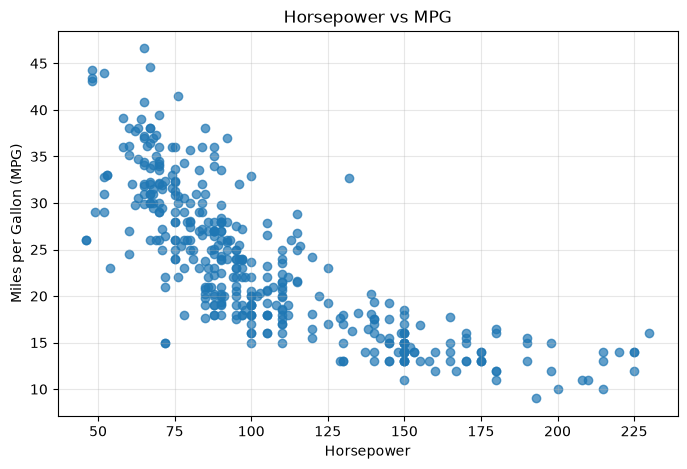

In [5]:
# 4. Visualize the relationship between horsepower and MPG

plt.figure(figsize=(8, 5))
plt.scatter(data["horsepower"], data["mpg"], alpha=0.7)
plt.title("Horsepower vs MPG")
plt.xlabel("Horsepower")
plt.ylabel("Miles per Gallon (MPG)")
plt.grid(True, alpha=0.3)
plt.show()

In [6]:
# 5. Split data into 80% training data and 20% testing data

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 313
Testing samples: 79


In [7]:
# 6. Fit models for the specified polynomial degrees

degrees = [1, 2, 3, 5, 8, 10]
results = []
models = {}

for degree in degrees:
    model = Pipeline([
        ("polynomial_features", PolynomialFeatures(degree=degree, include_bias=False)),
        ("scaler", StandardScaler()),
        ("linear_regression", LinearRegression())
    ])

    model.fit(X_train, y_train)

    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    train_mse = mean_squared_error(y_train, y_train_pred)
    test_mse = mean_squared_error(y_test, y_test_pred)

    results.append({
        "Polynomial Degree": degree,
        "Training MSE": train_mse,
        "Testing MSE": test_mse
    })
    models[degree] = model

results_df = pd.DataFrame(results)
display(results_df.round(3))

,Polynomial Degree,Training MSE,Testing MSE
0,1,24.475,22.153
1,2,19.205,18.417
2,3,19.144,18.460
3,5,18.644,17.877
4,8,18.434,17.023
5,10,18.414,17.186


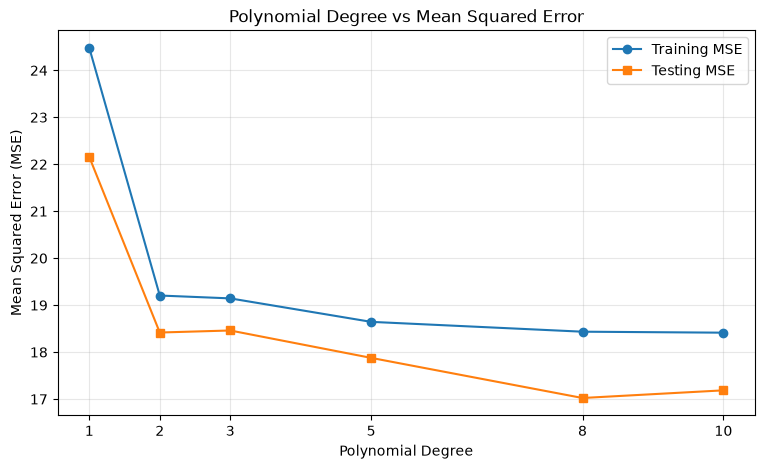

Best polynomial degree based on the minimum testing MSE: 8
Minimum testing MSE: 17.023


In [8]:
# 7. Plot the model complexity curve: degree vs training/testing MSE

plt.figure(figsize=(9, 5))
plt.plot(results_df["Polynomial Degree"], results_df["Training MSE"],
         marker="o", label="Training MSE")
plt.plot(results_df["Polynomial Degree"], results_df["Testing MSE"],
         marker="s", label="Testing MSE")
plt.title("Polynomial Degree vs Mean Squared Error")
plt.xlabel("Polynomial Degree")
plt.ylabel("Mean Squared Error (MSE)")
plt.xticks(degrees)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

best_row = results_df.loc[results_df["Testing MSE"].idxmin()]
best_degree = int(best_row["Polynomial Degree"])
print("Best polynomial degree based on the minimum testing MSE:", best_degree)
print("Minimum testing MSE:", round(float(best_row["Testing MSE"]), 3))

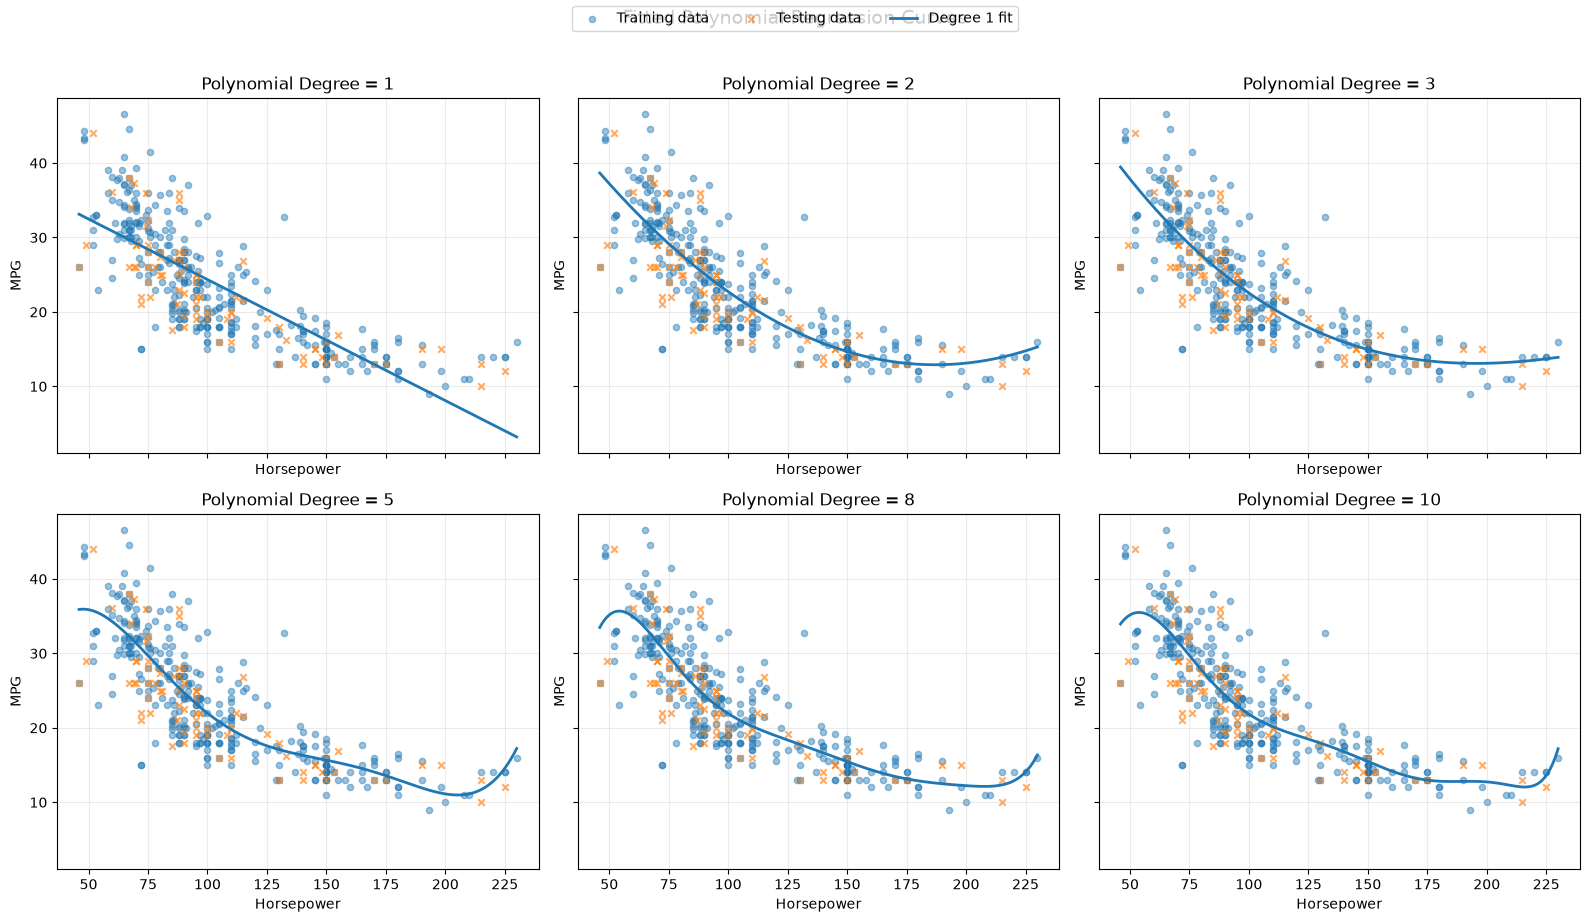

In [9]:
# 8. Visualize fitted polynomial curves for all degrees

x_grid = np.linspace(data["horsepower"].min(), data["horsepower"].max(), 300)
X_grid = pd.DataFrame({"horsepower": x_grid})

fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharex=True, sharey=True)
axes = axes.flatten()

for ax, degree in zip(axes, degrees):
    ax.scatter(X_train["horsepower"], y_train, alpha=0.45, s=20, label="Training data")
    ax.scatter(X_test["horsepower"], y_test, alpha=0.65, s=22, marker="x", label="Testing data")
    y_grid_pred = models[degree].predict(X_grid)
    ax.plot(x_grid, y_grid_pred, linewidth=2, label=f"Degree {degree} fit")
    ax.set_title(f"Polynomial Degree = {degree}")
    ax.set_xlabel("Horsepower")
    ax.set_ylabel("MPG")
    ax.grid(True, alpha=0.25)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3)
fig.suptitle("Fitted Polynomial Regression Curves", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

In [10]:
# 9. Compare the training and testing errors for the best degree

best_model = models[best_degree]
best_train_mse = mean_squared_error(y_train, best_model.predict(X_train))
best_test_mse = mean_squared_error(y_test, best_model.predict(X_test))

print(f"Selected degree: {best_degree}")
print(f"Training MSE: {best_train_mse:.3f}")
print(f"Testing MSE: {best_test_mse:.3f}")

Selected degree: 8
Training MSE: 18.434
Testing MSE: 17.023
